In [217]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [218]:
df = pd.read_csv('smartphone_train.csv')

In [219]:
df.drop(columns= 'subject', inplace= True)

In [220]:
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [221]:
df.shape

(7352, 562)

In [222]:
# converting categorical column into numerical for ml algos

In [223]:
df['Activity'].value_counts()

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

In [224]:
from sklearn.preprocessing import LabelEncoder

In [225]:
le = LabelEncoder()

In [226]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [227]:
le.fit_transform(y)

array([2, 2, 2, ..., 5, 5, 5], shape=(7352,))

In [228]:
from sklearn.model_selection import train_test_split

In [229]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [230]:
from sklearn.linear_model import LogisticRegression

In [231]:
lg = LogisticRegression(max_iter= 1000)

In [232]:
lg.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [233]:
from sklearn.metrics import accuracy_score

In [234]:
accuracy_score(y_test, lg.predict(X_test))

0.9809653297076818

In [235]:
# finding any duplicatye columns exists or not
def get_duplicates(df):
    duplicate_cols = {}
    for col in df.columns:
        duplicate_cols.setdefault(tuple(df[col].values), []).append(col)
    duplicate_cols = [val for key, val in duplicate_cols.items() if len(val) > 1]
    duplicate_cols = [name for col_name in duplicate_cols for j, name in enumerate(col_name) if (j!= 0)]
    return duplicate_cols

In [236]:
X_train.drop(columns= get_duplicates(X_train), inplace= True)
X_test.drop(columns = get_duplicates(X_test), inplace= True)

In [237]:
X_train.shape

(5881, 540)

In [238]:
X_test.shape

(1471, 540)

In [239]:
# another easy method to remove duplicates

In [240]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [241]:
X_train.shape

(5881, 561)

In [242]:
X_train.T.duplicated().value_counts()

False    540
True      21
Name: count, dtype: int64

In [243]:
X_train = X_train.T.drop_duplicates(keep= 'first').T

In [244]:
X_train.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
57,0.278007,-0.017803,-0.108965,-0.994425,-0.994873,-0.994886,-0.994939,-0.993994,-0.995450,-0.938974,...,0.394506,-0.684497,-0.901888,0.751089,0.626432,0.263401,-0.646225,0.398881,-0.546717,-0.431200
4154,0.237617,-0.000782,-0.114476,-0.326331,0.069663,-0.224321,-0.343326,0.039623,-0.256327,-0.310961,...,0.052089,-0.131946,-0.591721,0.628099,-0.357089,-0.925512,0.110212,-0.474013,0.383162,0.238969
6945,0.290924,-0.050878,-0.073518,-0.026220,-0.032163,0.393109,-0.118256,-0.030279,0.432861,0.370607,...,-0.038923,-0.643660,-0.935668,-0.182993,0.484857,-0.961034,0.147325,-0.819001,0.221549,-0.003571
527,0.275268,-0.015050,-0.114204,-0.981092,-0.901124,-0.960423,-0.984417,-0.901405,-0.965788,-0.922291,...,-0.145084,-0.326860,-0.645937,0.205896,-0.168239,-0.197557,0.328892,-0.744428,0.274256,0.031246
4196,0.278790,-0.018585,-0.106908,-0.997380,-0.983893,-0.984482,-0.997331,-0.985196,-0.983768,-0.942062,...,0.096524,-0.113724,-0.445144,-0.267371,-0.304399,-0.081555,0.110146,-0.615329,0.322236,0.161577


In [245]:
X_train.shape

(5881, 540)

In [246]:
X_test = X_test.T.drop_duplicates(keep= 'first').T

In [247]:
X_test.shape

(1471, 540)

In [248]:
from sklearn.feature_selection import VarianceThreshold

In [249]:
sel = VarianceThreshold(threshold= 0.05)

In [250]:
sel.fit(X_train)

VarianceThreshold(threshold=0.05)

In [251]:
# to calculate the variances of each featureabs
sel.variances_

array([0.00493011, 0.001801  , 0.00336611, 0.2015373 , 0.25205059,
       0.17483939, 0.17993763, 0.23547637, 0.17090435, 0.29567682,
       0.07982005, 0.08673712, 0.13194141, 0.1176714 , 0.08818797,
       0.22232326, 0.06723064, 0.01606945, 0.04977105, 0.13786893,
       0.13759382, 0.14823716, 0.22012491, 0.19156786, 0.13754301,
       0.09333435, 0.06044485, 0.05931908, 0.05276726, 0.06630334,
       0.04639672, 0.0435291 , 0.04832679, 0.08145574, 0.0468068 ,
       0.05533606, 0.05409058, 0.13458426, 0.11138376, 0.15026897,
       0.26704221, 0.13835987, 0.12191639, 0.00610622, 0.00919527,
       0.01204906, 0.00589585, 0.00900766, 0.01181178, 0.26019097,
       0.12993882, 0.11899672, 0.25875217, 0.13646624, 0.12336549,
       0.16291619, 0.48746942, 0.18898437, 0.19236145, 0.00533188,
       0.00838653, 0.01082969, 0.13296155, 0.08140575, 0.15894664,
       0.04537418, 0.04285879, 0.04224966, 0.0434703 , 0.08475955,
       0.08851927, 0.08421983, 0.07938266, 0.07303658, 0.06789

In [252]:
# to identify which features got selectedabs
sel.get_support()

array([False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False, False, False,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True, False, False,
       False, False, False, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False, False, False,  True,
        True,  True, False, False, False, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
       False, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False,  True, False,
        True,  True,  True,  True,  True,  True,  True, False,  True,
       False,  True, False,  True, False,  True, False,  True,  True,
        True,  True,  True, False, False, False,  True,  True,  True,
        True,  True,

In [253]:
selected_cols = X_train.columns[sel.get_support()]

In [254]:
selected_cols

Index(['tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z',
       'tBodyAcc-min()-X',
       ...
       'fBodyBodyGyroJerkMag-meanFreq()', 'fBodyBodyGyroJerkMag-skewness()',
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)'],
      dtype='object', length=349)

In [255]:
X_train = sel.transform(X_train)

In [256]:
X_train

array([[-0.9944254 , -0.99487263, -0.99488582, ...,  0.39888109,
        -0.54671715, -0.43119994],
       [-0.32633148,  0.0696628 , -0.22432128, ..., -0.47401293,
         0.38316244,  0.23896924],
       [-0.02621997, -0.03216306,  0.39310852, ..., -0.81900124,
         0.22154911, -0.00357091],
       ...,
       [-0.62719763, -0.21656585, -0.42476369, ..., -0.85651241,
         0.18354749, -0.03493857],
       [-0.9948248 , -0.98531367, -0.96585729, ..., -0.83969327,
         0.08138803, -0.09827024],
       [-0.36865452, -0.14263084, -0.15125003, ..., -0.86809289,
         0.18822594,  0.00274405]], shape=(5881, 349))

In [257]:
X_train = pd.DataFrame(X_train, columns= selected_cols)

In [258]:
X_train.head()

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,-0.994425,-0.994873,-0.994886,-0.994939,-0.993994,-0.995450,-0.938974,-0.577031,-0.813863,0.846922,...,0.394506,-0.684497,-0.901888,0.751089,0.626432,0.263401,-0.646225,0.398881,-0.546717,-0.431200
1,-0.326331,0.069663,-0.224321,-0.343326,0.039623,-0.256327,-0.310961,0.085617,-0.411806,0.271334,...,0.052089,-0.131946,-0.591721,0.628099,-0.357089,-0.925512,0.110212,-0.474013,0.383162,0.238969
2,-0.026220,-0.032163,0.393109,-0.118256,-0.030279,0.432861,0.370607,-0.072309,0.200747,0.118277,...,-0.038923,-0.643660,-0.935668,-0.182993,0.484857,-0.961034,0.147325,-0.819001,0.221549,-0.003571
3,-0.981092,-0.901124,-0.960423,-0.984417,-0.901405,-0.965788,-0.922291,-0.524676,-0.807362,0.825370,...,-0.145084,-0.326860,-0.645937,0.205896,-0.168239,-0.197557,0.328892,-0.744428,0.274256,0.031246
4,-0.997380,-0.983893,-0.984482,-0.997331,-0.985196,-0.983768,-0.942062,-0.564033,-0.810993,0.853330,...,0.096524,-0.113724,-0.445144,-0.267371,-0.304399,-0.081555,0.110146,-0.615329,0.322236,0.161577


In [259]:
X_test = sel.transform(X_test)

In [260]:
X_test = pd.DataFrame(X_test, columns= selected_cols)

In [261]:
X_test.head()

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.384949,0.176898,-0.310332,0.381757,0.122611,-0.332984,0.465563,0.023174,-0.274788,-0.176416,...,0.454181,-0.730593,-0.932568,-0.034924,0.558036,0.258975,-0.854858,-0.784330,0.222960,-0.066506
1,0.201409,-0.154142,0.344183,0.092771,-0.182114,0.291899,0.586004,-0.089706,-0.307547,0.201299,...,0.190745,-0.032958,-0.338095,0.017986,-0.475545,0.942947,-0.567147,-0.665156,0.178975,0.243362
2,-0.336609,-0.279162,-0.303323,-0.381421,-0.253026,-0.337381,0.074430,-0.228225,-0.346372,0.339322,...,0.299767,-0.351997,-0.698254,-0.044663,-0.551806,-0.680774,0.161405,-0.857202,0.192929,0.046716
3,-0.992196,-0.982169,-0.981127,-0.992838,-0.981366,-0.979864,-0.931924,-0.560341,-0.809997,0.840250,...,0.335848,-0.623358,-0.906098,-0.177275,-0.309304,0.176515,-0.143818,-0.625215,-0.106678,-0.147469
4,0.075014,0.046502,-0.369482,-0.024794,-0.085337,-0.385018,0.562230,0.093312,-0.200019,0.213969,...,-0.125979,0.020630,-0.316113,0.347143,0.590475,0.831084,0.465453,-0.860617,0.150598,-0.067109


In [275]:
corr_matrix = X_train.corr()

In [276]:
import seaborn as sns

<Axes: >

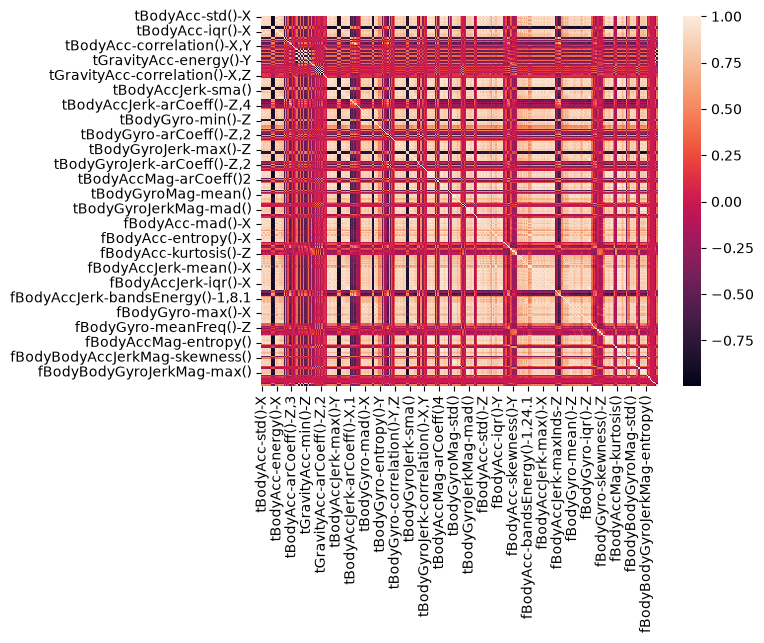

In [277]:
sns.heatmap(X_train.corr())

In [283]:
multicolls = []
for i in range(X_train.shape[1]):
    for j in range(i + 1, X_train.shape[1]):
        if ((corr_matrix.iloc[i, j]) > 0.95):
            multicolls.append(X_train.columns[j])
multicolls

['tBodyAcc-mad()-X',
 'tBodyAcc-max()-X',
 'tBodyAcc-sma()',
 'tBodyAcc-iqr()-X',
 'tBodyAccJerk-std()-X',
 'tBodyAccJerk-mad()-X',
 'tBodyAccJerk-sma()',
 'tBodyAccJerk-iqr()-X',
 'tBodyAccMag-mean()',
 'tBodyAccMag-std()',
 'tBodyAccMag-mad()',
 'tBodyAccMag-max()',
 'tBodyAccMag-energy()',
 'tBodyAccJerkMag-mean()',
 'tBodyAccJerkMag-std()',
 'tBodyAccJerkMag-mad()',
 'fBodyAcc-mean()-X',
 'fBodyAcc-std()-X',
 'fBodyAcc-mad()-X',
 'fBodyAcc-max()-X',
 'fBodyAcc-sma()',
 'fBodyAccJerk-mean()-X',
 'fBodyAccJerk-std()-X',
 'fBodyAccJerk-mad()-X',
 'fBodyAccJerk-max()-X',
 'fBodyAccJerk-sma()',
 'fBodyAccMag-mean()',
 'fBodyAccMag-std()',
 'fBodyAccMag-mad()',
 'fBodyBodyAccJerkMag-mean()',
 'tBodyAcc-mad()-Y',
 'tBodyAcc-max()-Y',
 'tBodyAcc-sma()',
 'tBodyAcc-iqr()-Y',
 'tBodyAccJerk-std()-Y',
 'tBodyAccJerk-mad()-Y',
 'tBodyAccJerk-iqr()-Y',
 'tBodyGyro-sma()',
 'tBodyAccMag-mean()',
 'tBodyAccJerkMag-entropy()',
 'tBodyGyroMag-mean()',
 'fBodyAcc-mean()-Y',
 'fBodyAcc-std()-Y',
 'fB

In [284]:
multicolls = set(multicolls)

In [285]:
len(multicolls)

197

In [286]:
multicolls

{'fBodyAcc-bandsEnergy()-1,16',
 'fBodyAcc-bandsEnergy()-1,16.1',
 'fBodyAcc-bandsEnergy()-1,16.2',
 'fBodyAcc-bandsEnergy()-1,24',
 'fBodyAcc-bandsEnergy()-1,24.1',
 'fBodyAcc-bandsEnergy()-1,24.2',
 'fBodyAcc-bandsEnergy()-1,8',
 'fBodyAcc-bandsEnergy()-17,32',
 'fBodyAcc-energy()-X',
 'fBodyAcc-energy()-Y',
 'fBodyAcc-entropy()-X',
 'fBodyAcc-entropy()-Y',
 'fBodyAcc-entropy()-Z',
 'fBodyAcc-iqr()-X',
 'fBodyAcc-iqr()-Y',
 'fBodyAcc-iqr()-Z',
 'fBodyAcc-kurtosis()-X',
 'fBodyAcc-kurtosis()-Y',
 'fBodyAcc-kurtosis()-Z',
 'fBodyAcc-mad()-X',
 'fBodyAcc-mad()-Y',
 'fBodyAcc-mad()-Z',
 'fBodyAcc-max()-X',
 'fBodyAcc-max()-Y',
 'fBodyAcc-max()-Z',
 'fBodyAcc-mean()-X',
 'fBodyAcc-mean()-Y',
 'fBodyAcc-mean()-Z',
 'fBodyAcc-sma()',
 'fBodyAcc-std()-X',
 'fBodyAcc-std()-Y',
 'fBodyAcc-std()-Z',
 'fBodyAccJerk-bandsEnergy()-1,16.1',
 'fBodyAccJerk-bandsEnergy()-1,24.1',
 'fBodyAccJerk-bandsEnergy()-17,24.1',
 'fBodyAccJerk-bandsEnergy()-17,32',
 'fBodyAccJerk-bandsEnergy()-17,32.1',
 'fBody

In [287]:
X_train = X_train.drop(columns= multicolls)
X_test = X_test.drop(columns = multicolls)

In [288]:
X_train.head()

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,...,fBodyBodyGyroMag-skewness(),fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,-0.994425,-0.994873,-0.994886,-0.813863,0.846922,0.691468,0.846423,-0.611174,-0.768785,-0.663066,...,0.043182,0.394506,-0.684497,0.751089,0.626432,0.263401,-0.646225,0.398881,-0.546717,-0.431200
1,-0.326331,0.069663,-0.224321,-0.411806,0.271334,0.039452,0.269204,0.403663,0.180054,0.176069,...,-0.225796,0.052089,-0.131946,0.628099,-0.357089,-0.925512,0.110212,-0.474013,0.383162,0.238969
2,-0.026220,-0.032163,0.393109,0.200747,0.118277,0.072295,0.245986,0.318557,0.135103,0.087680,...,-0.346388,-0.038923,-0.643660,-0.182993,0.484857,-0.961034,0.147325,-0.819001,0.221549,-0.003571
3,-0.981092,-0.901124,-0.960423,-0.807362,0.825370,0.642789,0.815368,-0.376515,-0.171730,-0.496816,...,0.197311,-0.145084,-0.326860,0.205896,-0.168239,-0.197557,0.328892,-0.744428,0.274256,0.031246
4,-0.997380,-0.983893,-0.984482,-0.810993,0.853330,0.687431,0.844895,-0.652548,-0.678458,-0.486837,...,0.310607,0.096524,-0.113724,-0.267371,-0.304399,-0.081555,0.110146,-0.615329,0.322236,0.161577


In [289]:
# feature_selection using anova

In [290]:
from sklearn.feature_selection import f_classif, SelectKBest

In [291]:
sel = SelectKBest(score_func= f_classif, k = 100).fit(X_train, y_train)

In [292]:
cols = X_train.columns[sel.get_support()]

In [294]:
len(cols)

100

In [295]:
X_train = pd.DataFrame(sel.transform(X_train), columns= cols)
X_test = pd.DataFrame(sel.transform(X_test), columns = cols)

In [296]:
X_train.head()

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,...,fBodyGyro-meanFreq()-Z,"fBodyGyro-bandsEnergy()-1,8.1",fBodyAccMag-maxInds,fBodyBodyAccJerkMag-min(),fBodyBodyAccJerkMag-meanFreq(),fBodyBodyAccJerkMag-skewness(),fBodyBodyGyroMag-meanFreq(),"angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,-0.994425,-0.994873,-0.994886,-0.813863,0.846922,0.691468,0.846423,-0.611174,-0.768785,-0.663066,...,-0.158283,-0.999962,0.172414,-0.986305,0.132640,-0.690000,-0.024257,0.398881,-0.546717,-0.431200
1,-0.326331,0.069663,-0.224321,-0.411806,0.271334,0.039452,0.269204,0.403663,0.180054,0.176069,...,-0.315738,-0.898022,-0.517241,-0.718822,0.144767,-0.316666,0.191186,-0.474013,0.383162,0.238969
2,-0.026220,-0.032163,0.393109,0.200747,0.118277,0.072295,0.245986,0.318557,0.135103,0.087680,...,-0.071045,0.192158,-0.793103,-0.290424,-0.088077,-0.270995,-0.431985,-0.819001,0.221549,-0.003571
3,-0.981092,-0.901124,-0.960423,-0.807362,0.825370,0.642789,0.815368,-0.376515,-0.171730,-0.496816,...,-0.629423,-0.996263,-0.931034,-0.997886,-0.027783,-0.651181,-0.567748,-0.744428,0.274256,0.031246
4,-0.997380,-0.983893,-0.984482,-0.810993,0.853330,0.687431,0.844895,-0.652548,-0.678458,-0.486837,...,0.261846,-0.999927,-1.000000,-0.988139,0.668020,-0.598248,-0.257360,-0.615329,0.322236,0.161577


In [297]:
# another way to select based on p values(drop columns if p value >0.05)
from sklearn.feature_selection import SelectFpr

In [298]:
sel = SelectFpr(score_func= f_classif, alpha= 0.05)

In [299]:
sel.fit(X_train, y_train)

SelectFpr()

In [307]:
X_train.shape

(5881, 100)

In [308]:
X_test.shape

(1471, 100)

In [309]:
# now again training the lLogisticRegression

In [310]:
lg2 = LogisticRegression(max_iter= 1000)

In [311]:
lg2.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [312]:
accuracy_score(y_test, lg2.predict(X_test))

0.9687287559483345

In [313]:
df = pd.read_csv('titanic.csv')

In [314]:
df.head()

,Passengerid,Age,Fare,Sex,sibsp,zero,zero.1,zero.2,zero.3,zero.4,...,zero.12,zero.13,zero.14,Pclass,zero.15,zero.16,Embarked,zero.17,zero.18,2urvived
0,1,22.0,7.2500,0,1,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,0
1,2,38.0,71.2833,1,1,0,0,0,0,0,...,0,0,0,1,0,0,0.0,0,0,1
2,3,26.0,7.9250,1,0,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,1
3,4,35.0,53.1000,1,1,0,0,0,0,0,...,0,0,0,1,0,0,2.0,0,0,1
4,5,35.0,8.0500,0,0,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,0


In [315]:
df = df[['Sex', 'sibsp', '2urvived']]

In [318]:
df = df.rename(columns= {'2urvived': 'Survived'})

In [319]:
df.head()

,Sex,sibsp,Survived
0,0,1,0
1,1,1,1
2,1,0,1
3,1,1,1
4,0,0,0


In [333]:
score = {}

from scipy.stats import chi2_contingency
for i in df.columns[:-1]:
    ct = pd.crosstab(df['Survived'], df[i])
    p_value = chi2_contingency(ct)[1]
    score[i] = p_value

{'Sex': np.float64(5.689442655436654e-48),
 'sibsp': np.float64(0.0004529019256813581)}

In [339]:
cols = [key for key, value in score.items() if value > 0.05] 

In [340]:
cols

[]

In [342]:
df = df.drop(columns = cols)

In [343]:
df.head()

,Sex,sibsp,Survived
0,0,1,0
1,1,1,1
2,1,0,1
3,1,1,1
4,0,0,0
